# 🍲 Exploratory Data Analysis (EDA): Prevalensi Kerawanan Pangan (FIES) Provinsi di Indonesia (2017–2025)

**Mata Kuliah:** Presentasi dan Storytelling Data  
**Topik:** Evaluasi Akses Pangan Layak (SDG Indikator 2.1.2) Tingkat Provinsi  
**Dataset:** `dataset_provinsi/` (9 Berkas CSV Rilis Tahunan BPS 2017–2025)  

---

## 📌 1. Latar Belakang & Konteks Analisis
**Food Insecurity Experience Scale (FIES)** atau **Skala Pengalaman Kerawanan Pangan** adalah metodologi berbasis survei pengalaman individu/rumah tangga yang dirintis oleh Organisasi Pangan dan Pertanian Dunia (FAO) dan diadopsi secara resmi oleh Badan Pusat Statistik (BPS) sebagai **Indikator SDG 2.1.2**.

FIES mengukur prevalensi penduduk yang mengalami **kerawanan pangan tingkat sedang (*moderate*) atau berat (*severe*)**:
- **Kerawanan Pangan Sedang:** Ketidakpastian dalam memperoleh makanan, terpaksa mengorbankan kualitas dan variasi makanan, atau mengurangi porsi makan akibat kendala ekonomi.
- **Kerawanan Pangan Berat:** Kehabisan makanan sama sekali, mengalami kelaparan fisik, atau bahkan tidak makan seharian penuh.

Keunggulan FIES adalah kemampuannya menangkap **pengalaman psikologis dan perilaku nyata rumah tangga** saat menghadapi kesulitan pangan, menjadikannya komplemen krusial bagi data kemiskinan moneter (P0) dan data kalori makro (PoU).

Notebook ini menyatukan 9 tahun data BPS (2017–2025) dari seluruh provinsi di Indonesia untuk menelusuri kisah sukses penurunan kerawanan pangan nasional, memetakan jurang kesenjangan antar-pulau, serta menganalisis kondisi provinsi pemekaran baru di Papua.


In [1]:
# Setup library analisis data & visualisasi
import os
import glob
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi estetika visualisasi
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['figure.autolayout'] = True
sns.set_palette('tab10')

print("✅ Library analisis berhasil dimuat!")


✅ Library analisis berhasil dimuat!


## 🧹 2. Pemuatan & Pembersihan Data (Data Ingestion & Preprocessing)

Data `dataset_provinsi` terdiri dari 9 berkas CSV (2017–2025). Terdapat beberapa catatan kualitas data:
1. **Tanda '-' pada Provinsi Baru:** Dari 2017 hingga 2023, 4 provinsi pemekaran baru Papua (Papua Barat Daya, Papua Selatan, Papua Tengah, Papua Pegunungan) belum dibentuk, sehingga dicatat dengan tanda `-`. Tanda ini diubah menjadi `NaN`. Pada 2024–2025, keempat provinsi memiliki nilai numerik lengkap.
2. **Entitas 'INDONESIA':** Merupakan nilai rerata agregat nasional.
3. **Pengelompokan Wilayah Pulau:** Provinsi dikelompokkan ke dalam 7 gugus kepulauan besar (Sumatera, Jawa, Bali & Nusa Tenggara, Kalimantan, Sulawesi, Maluku, Papua).


In [2]:
# Mengumpulkan berkas CSV kerawanan pangan provinsi
raw_data_dir = os.path.join('..', 'data', 'raw') if os.path.exists(os.path.join('..', 'data', 'raw')) else (os.path.join('data', 'raw') if os.path.exists(os.path.join('data', 'raw')) else '.')
prov_files = sorted(glob.glob(os.path.join(raw_data_dir, 'dataset_provinsi', '*.csv')))
print(f"Ditemukan {len(prov_files)} berkas CSV di dataset_provinsi:")

dfs_long = []
dfs_wide = []

for f in prov_files:
    # Ekstrak tahun
    match = re.search(r'(\d{4})', os.path.basename(f))
    year = int(match.group(1))
    
    # Baca data dengan skiprows=3
    df_temp = pd.read_csv(f, skiprows=3, names=['provinsi', 'fies'], encoding='utf-8')
    df_temp['provinsi'] = df_temp['provinsi'].str.strip()
    df_temp['fies'] = pd.to_numeric(df_temp['fies'].replace('-', pd.NA), errors='coerce')
    df_temp['tahun'] = year
    
    dfs_long.append(df_temp)
    dfs_wide.append(df_temp.set_index('provinsi')[['fies']].rename(columns={'fies': f'fies_{year}'}))

# 1. Long panel
df_fies_all = pd.concat(dfs_long, ignore_index=True)

# 2. Wide format
df_fies_wide = pd.concat(dfs_wide, axis=1).reset_index()

# 3. Klasifikasi Pulau
def get_pulau(prov):
    prov = str(prov).upper()
    if any(p in prov for p in ['ACEH', 'SUMATERA', 'RIAU', 'JAMBI', 'BENGKULU', 'LAMPUNG', 'BANGKA', 'BELITUNG']):
        return 'Sumatera'
    elif any(p in prov for p in ['JAKARTA', 'JAWA', 'YOGYAKARTA', 'BANTEN']):
        return 'Jawa'
    elif any(p in prov for p in ['BALI', 'NUSA TENGGARA']):
        return 'Bali & Nusa Tenggara'
    elif 'KALIMANTAN' in prov:
        return 'Kalimantan'
    elif any(p in prov for p in ['SULAWESI', 'GORONTALO']):
        return 'Sulawesi'
    elif 'MALUKU' in prov:
        return 'Maluku'
    elif 'PAPUA' in prov:
        return 'Papua'
    return 'Nasional'

df_fies_all['wilayah_pulau'] = df_fies_all['provinsi'].apply(get_pulau)

# Pisahkan data provinsi dengan benchmark nasional
df_fies_nasional = df_fies_all[df_fies_all['provinsi'] == 'INDONESIA'].copy()
df_fies_prov = df_fies_all[df_fies_all['provinsi'] != 'INDONESIA'].copy()

print(f"Data Panel Keseluruhan: {df_fies_all.shape[0]} baris")
print(f"Data Provinsi          : {df_fies_prov.shape[0]} baris ({df_fies_prov['provinsi'].nunique()} provinsi)")
print(f"Tahun Observasi        : {sorted(df_fies_all['tahun'].unique())}")


Ditemukan 9 berkas CSV di dataset_provinsi:


Data Panel Keseluruhan: 351 baris


Data Provinsi          : 342 baris (38 provinsi)
Tahun Observasi        : [np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]


## 📊 3. Struktur Data & Statistik Ringkasan (Data Profiling)

Mari kita amati ringkasan statistik tingkat kerawanan pangan provinsi dari tahun ke tahun.


In [3]:
# Statistik Deskriptif Tahunan FIES Provinsi
stats_fies = df_fies_prov.groupby('tahun')['fies'].agg(
    jumlah_provinsi='count',
    rerata='mean',
    median='median',
    standar_deviasi='std',
    minimum='min',
    maksimum='max'
).reset_index()

print("=== STATISTIK RINGKASAN FIES PROVINSI (2017–2025) ===")
display(stats_fies.round(2))

print("\n=== TREN BENCHMARK NASIONAL 'INDONESIA' ===")
display(df_fies_nasional[['tahun', 'fies']].round(2))


=== STATISTIK RINGKASAN FIES PROVINSI (2017–2025) ===


,tahun,jumlah_provinsi,rerata,median,standar_deviasi,minimum,maksimum
0,2017,34,10.02,9.10,4.56,3.97,27.54
1,2018,34,8.45,7.40,3.96,3.14,21.32
2,2019,34,6.88,6.36,3.05,2.68,14.99
3,2020,34,6.15,5.62,3.07,1.84,15.46
4,2021,34,6.04,5.26,2.73,2.87,15.31
5,2022,34,5.61,5.11,2.68,2.16,14.48
6,2023,34,5.43,4.64,2.88,2.17,14.68
7,2024,38,5.35,4.14,3.78,0.76,18.13
8,2025,38,5.21,4.52,2.97,1.28,13.69



=== TREN BENCHMARK NASIONAL 'INDONESIA' ===


,tahun,fies
38,2017,8.66
77,2018,6.86
116,2019,5.42
155,2020,5.12
194,2021,4.79
233,2022,4.85
272,2023,4.50
311,2024,4.02
350,2025,4.00


## 📈 4. Analisis Tren Nasional Kerawanan Pangan Sedang/Berat (2017–2025)

**Kisah Sukses Besar Ketahanan Pangan Indonesia:**
Data resmi BPS membuktikan bahwa prevalensi kerawanan pangan sedang atau berat nasional **terpangkas lebih dari separuh (turun 53,8%)**, dari **8,66% pada tahun 2017 menjadi 4,00% pada tahun 2025**!


findfont: Failed to find font weight semibold, now using 700.


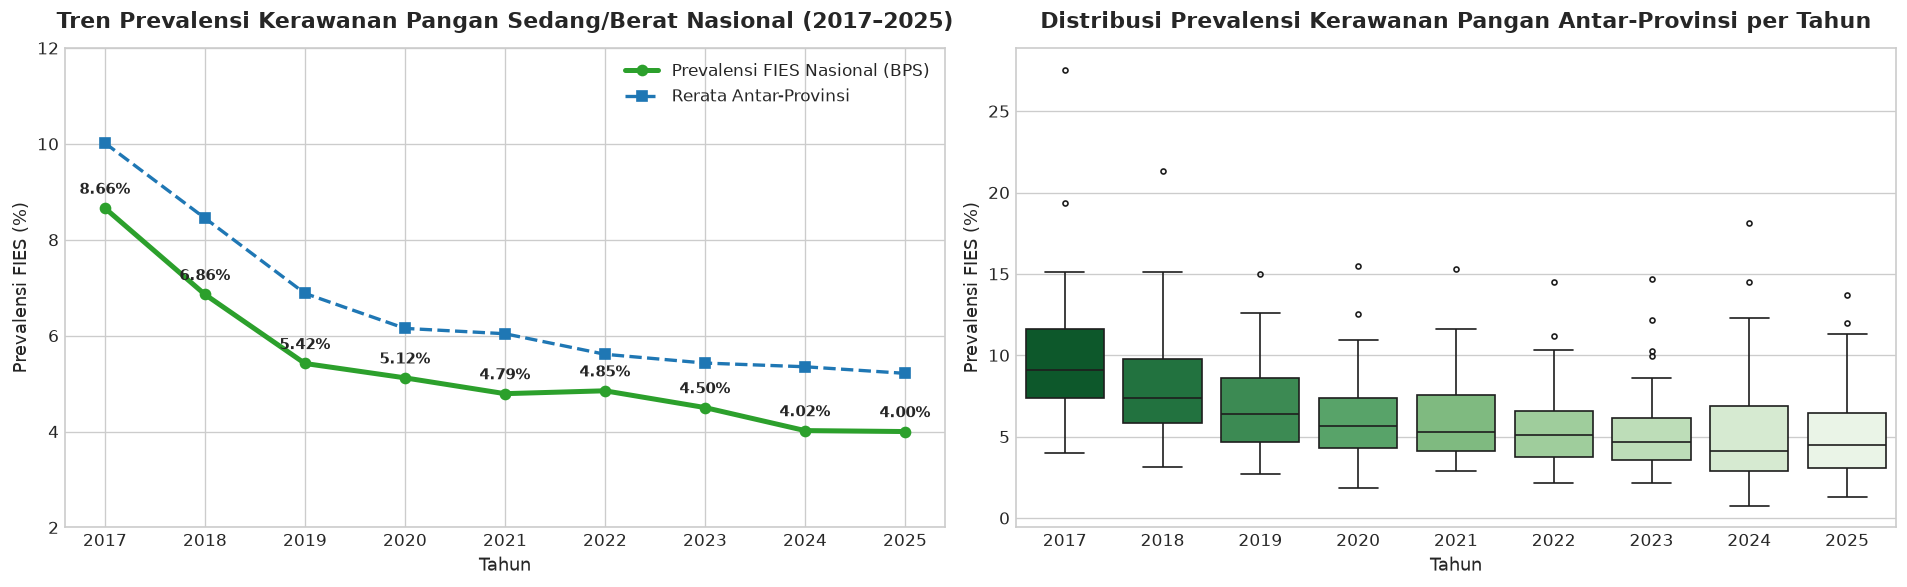

In [4]:
# Visualisasi Tren FIES Nasional vs Rerata Provinsi
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Line chart tren nasional
axes[0].plot(df_fies_nasional['tahun'], df_fies_nasional['fies'], marker='o', linewidth=3, color='#2ca02c', label='Prevalensi FIES Nasional (BPS)')
axes[0].plot(stats_fies['tahun'], stats_fies['rerata'], marker='s', linewidth=2, color='#1f77b4', linestyle='--', label='Rerata Antar-Provinsi')
axes[0].set_title('Tren Prevalensi Kerawanan Pangan Sedang/Berat Nasional (2017–2025)', fontsize=13, fontweight='bold', pad=12)
axes[0].set_xlabel('Tahun', fontsize=11)
axes[0].set_ylabel('Prevalensi FIES (%)', fontsize=11)
axes[0].set_ylim(2, 12)
axes[0].legend(loc='upper right')

for idx, r in df_fies_nasional.iterrows():
    axes[0].annotate(f"{r['fies']:.2f}%", (r['tahun'], r['fies'] + 0.3), ha='center', fontsize=9, fontweight='semibold')

# Plot 2: Boxplot sebaran kerawanan pangan antar-provinsi
sns.boxplot(data=df_fies_prov, x='tahun', y='fies', palette='Greens_r', ax=axes[1], fliersize=3)
axes[1].set_title('Distribusi Prevalensi Kerawanan Pangan Antar-Provinsi per Tahun', fontsize=13, fontweight='bold', pad=12)
axes[1].set_xlabel('Tahun', fontsize=11)
axes[1].set_ylabel('Prevalensi FIES (%)', fontsize=11)

plt.tight_layout()
plt.show()


## 🌡️ 5. Matriks Heatmap Kerawanan Pangan 38 Provinsi (2017–2025)

Heatmap di bawah ini menyajikan lanskap komprehensif tingkat kerawanan pangan seluruh provinsi di Indonesia selama kurun waktu 9 tahun. 
- Warna **merah tua** mencerminkan kerawanan pangan tinggi (> 10%).
- Warna **kuning/hijau muda** mencerminkan kerawanan pangan rendah (< 4%).


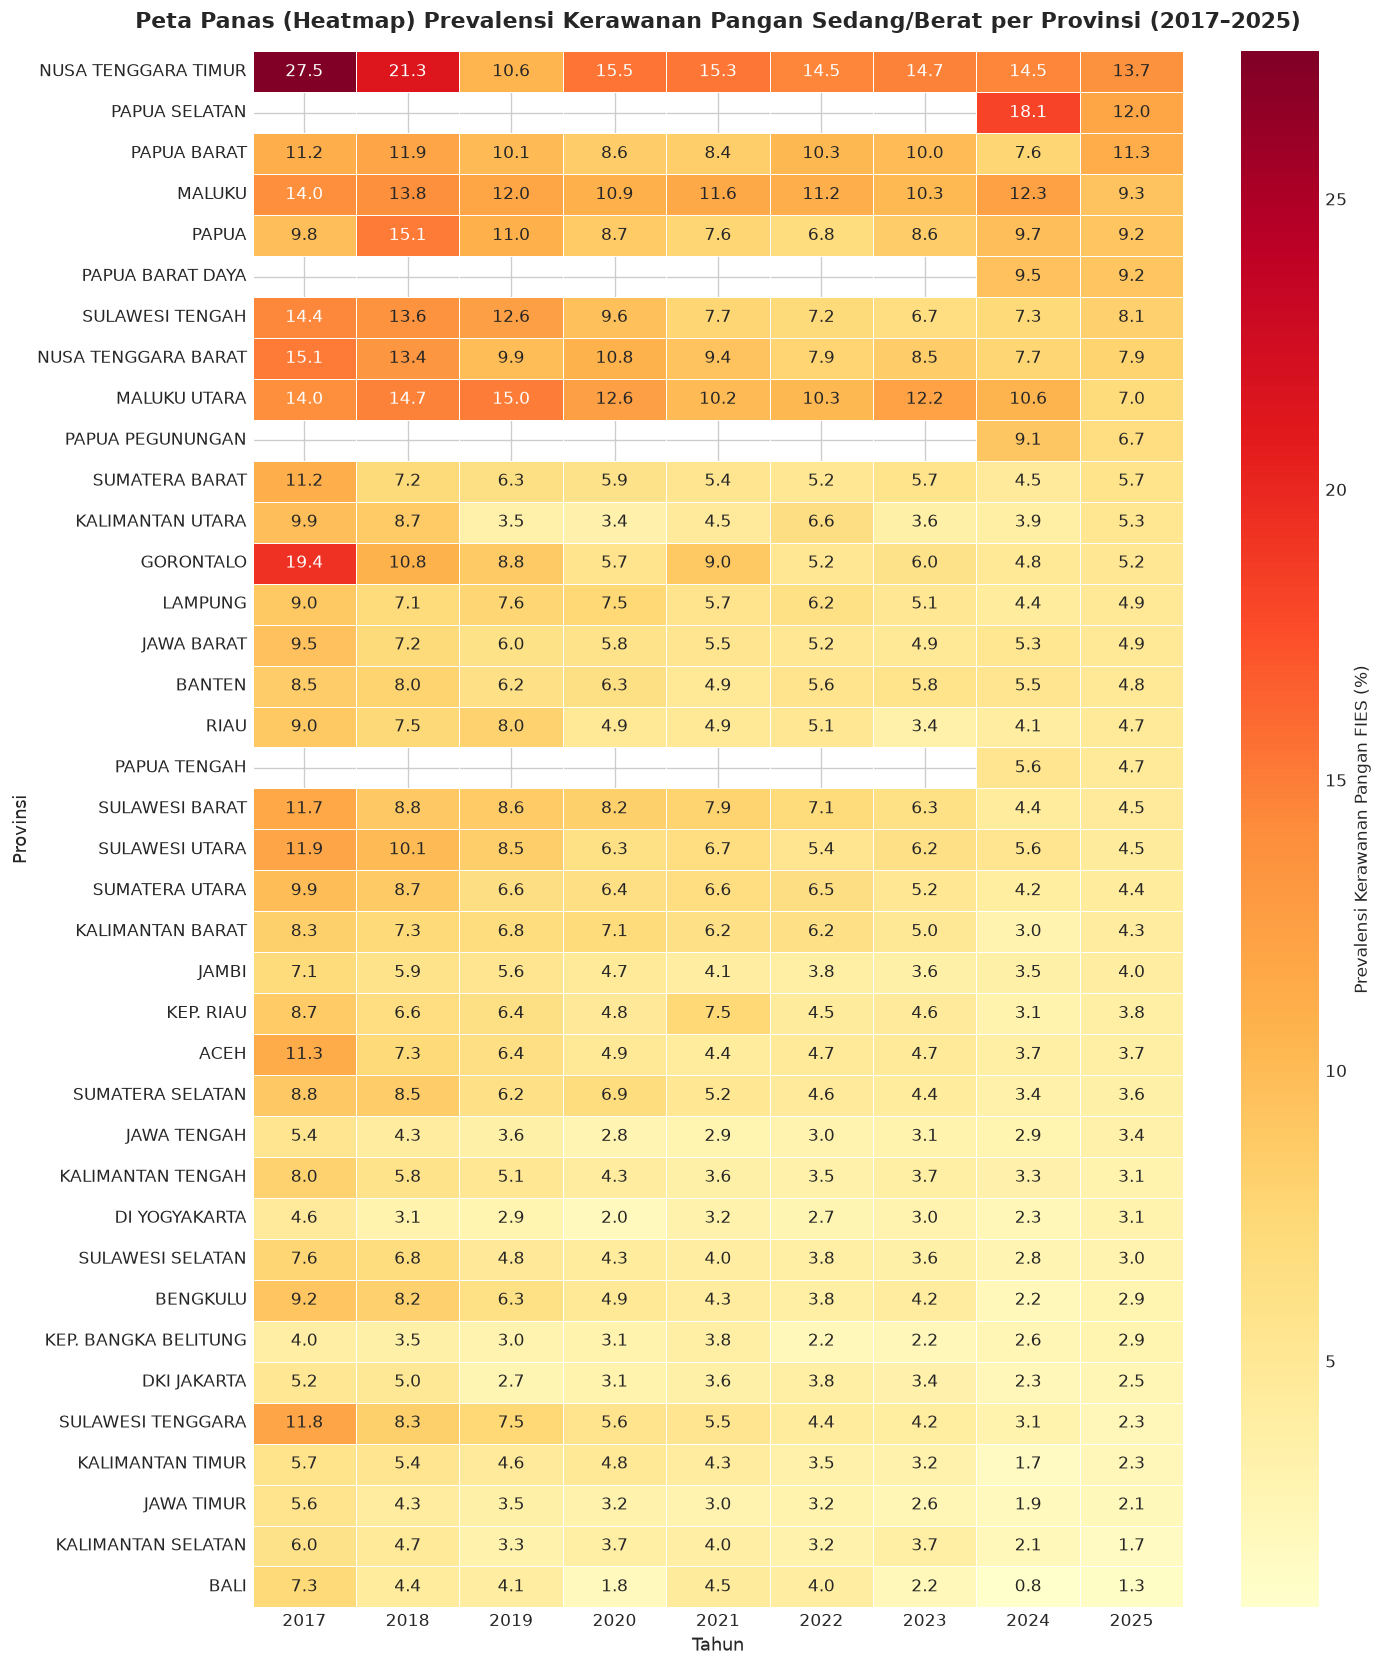

In [5]:
# Pivot table untuk heatmap
pivot_fies = df_fies_prov.pivot(index='provinsi', columns='tahun', values='fies')

# Urutkan berdasarkan data tahun 2025
pivot_fies = pivot_fies.sort_values(by=2025, ascending=False)

plt.figure(figsize=(12, 14))
sns.heatmap(pivot_fies, cmap='YlOrRd', annot=True, fmt='.1f', linewidths=0.5, cbar_kws={'label': 'Prevalensi Kerawanan Pangan FIES (%)'})
plt.title('Peta Panas (Heatmap) Prevalensi Kerawanan Pangan Sedang/Berat per Provinsi (2017–2025)', fontsize=13, fontweight='bold', pad=14)
plt.xlabel('Tahun', fontsize=11)
plt.ylabel('Provinsi', fontsize=11)
plt.tight_layout()
plt.show()


## 🏆 6. Pemeringkatan Seluruh Provinsi di Indonesia (Tahun Mutakhir 2025)

Mari kita amati posisi setiap provinsi pada tahun 2025 relatif terhadap rata-rata nasional (4,00%).


findfont: Failed to find font weight semibold, now using 700.


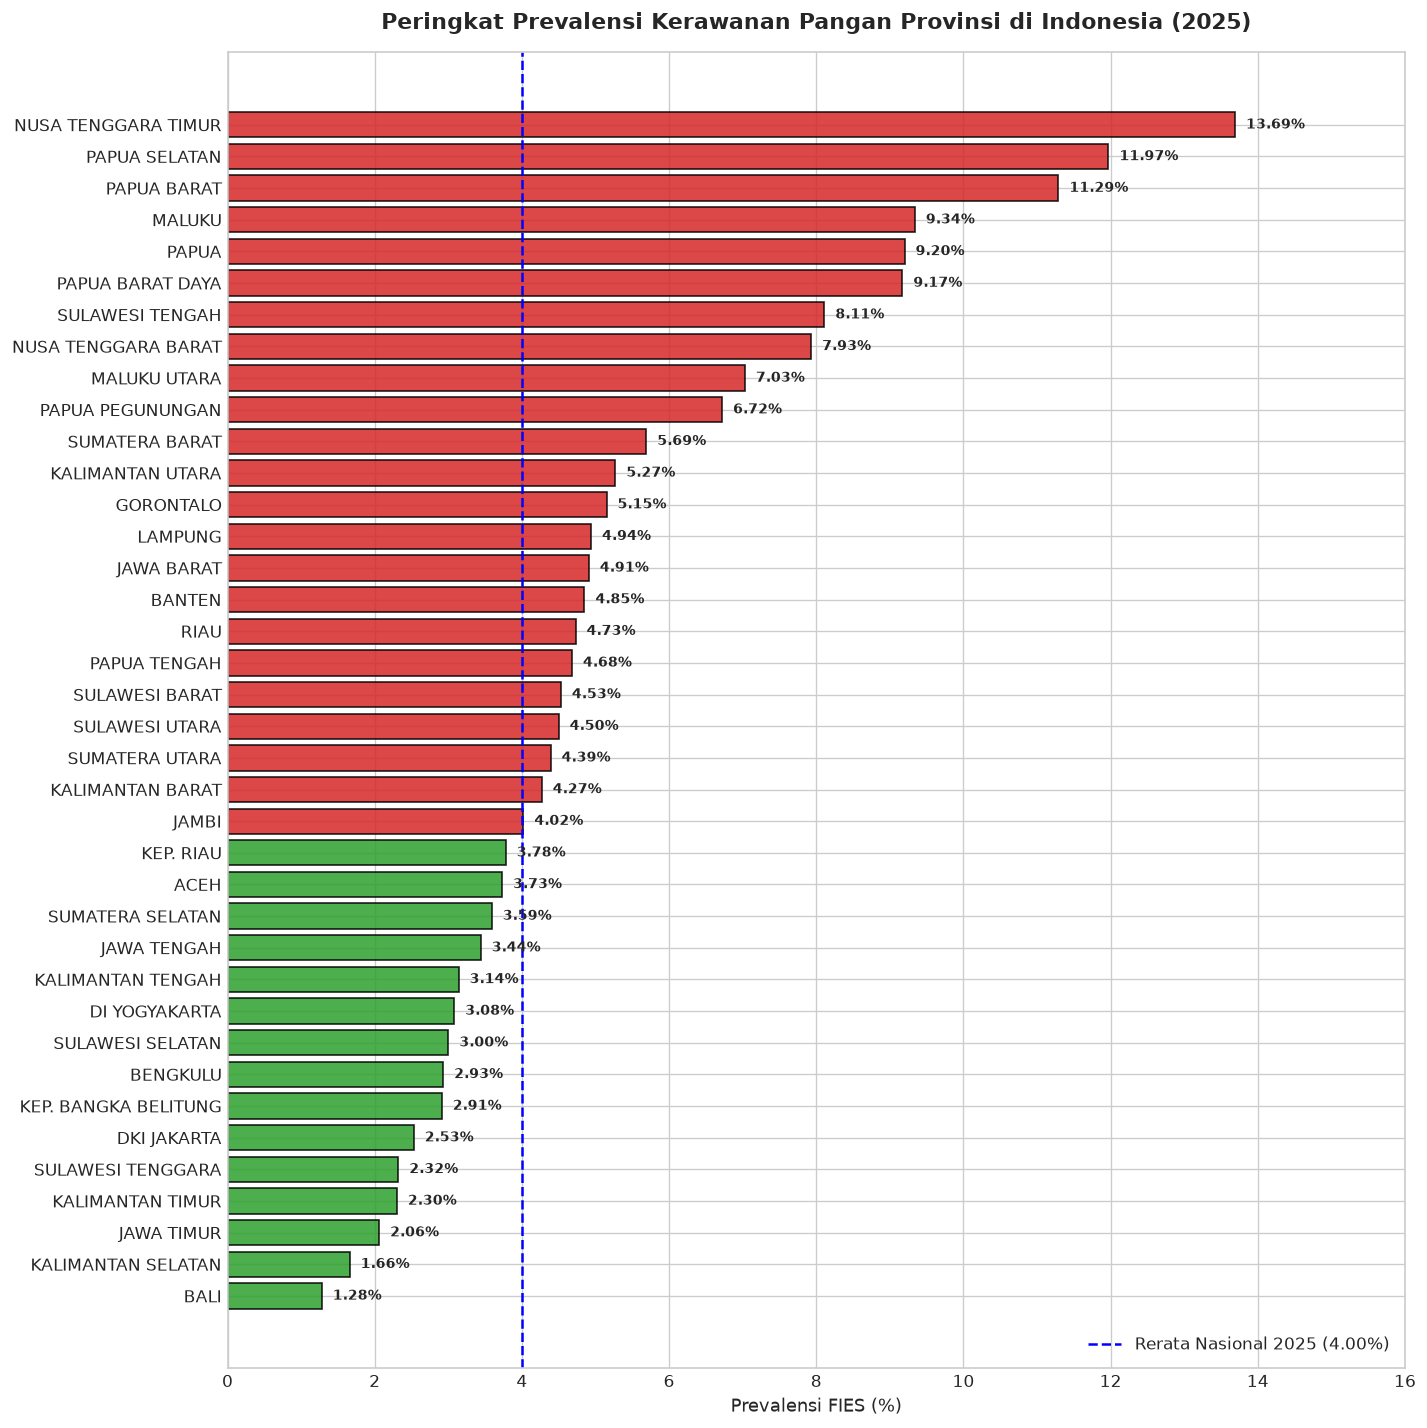

5 Provinsi dengan Kerawanan Pangan Terendah (Paling Mandiri):


,provinsi,fies
328,BALI,1.28
333,KALIMANTAN SELATAN,1.66
326,JAWA TIMUR,2.06
334,KALIMANTAN TIMUR,2.30
339,SULAWESI TENGGARA,2.32



5 Provinsi dengan Kerawanan Pangan Tertinggi (Paling Rawan):


,provinsi,fies
346,PAPUA,9.20
342,MALUKU,9.34
344,PAPUA BARAT,11.29
347,PAPUA SELATAN,11.97
330,NUSA TENGGARA TIMUR,13.69


In [6]:
# Barplot Horizontal Semua Provinsi 2025
df_2025 = df_fies_prov[df_fies_prov['tahun'] == 2025].sort_values('fies', ascending=True)

plt.figure(figsize=(12, 12))
colors = ['#d62728' if x > 4.00 else '#2ca02c' for x in df_2025['fies']]
bars = plt.barh(df_2025['provinsi'], df_2025['fies'], color=colors, edgecolor='black', alpha=0.85)

plt.axvline(x=4.00, color='blue', linestyle='--', linewidth=1.5, label='Rerata Nasional 2025 (4.00%)')
plt.title('Peringkat Prevalensi Kerawanan Pangan Provinsi di Indonesia (2025)', fontsize=13, fontweight='bold', pad=14)
plt.xlabel('Prevalensi FIES (%)', fontsize=11)
plt.ylabel('')
plt.xlim(0, 16)
plt.legend(loc='lower right')

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.15, bar.get_y() + bar.get_height()/2, f"{w:.2f}%", va='center', fontsize=8.5, fontweight='semibold')

plt.tight_layout()
plt.show()

print("5 Provinsi dengan Kerawanan Pangan Terendah (Paling Mandiri):")
display(df_2025.head(5)[['provinsi', 'fies']].round(2))

print("\n5 Provinsi dengan Kerawanan Pangan Tertinggi (Paling Rawan):")
display(df_2025.tail(5)[['provinsi', 'fies']].round(2))


## 🏝️ 7. Disparitas Kerawanan Pangan Antar-Gugus Kepulauan

Bagaimana ketahanan pangan berbasis pengalaman FIES bila dibandingkan antar kawasan geografis Indonesia?


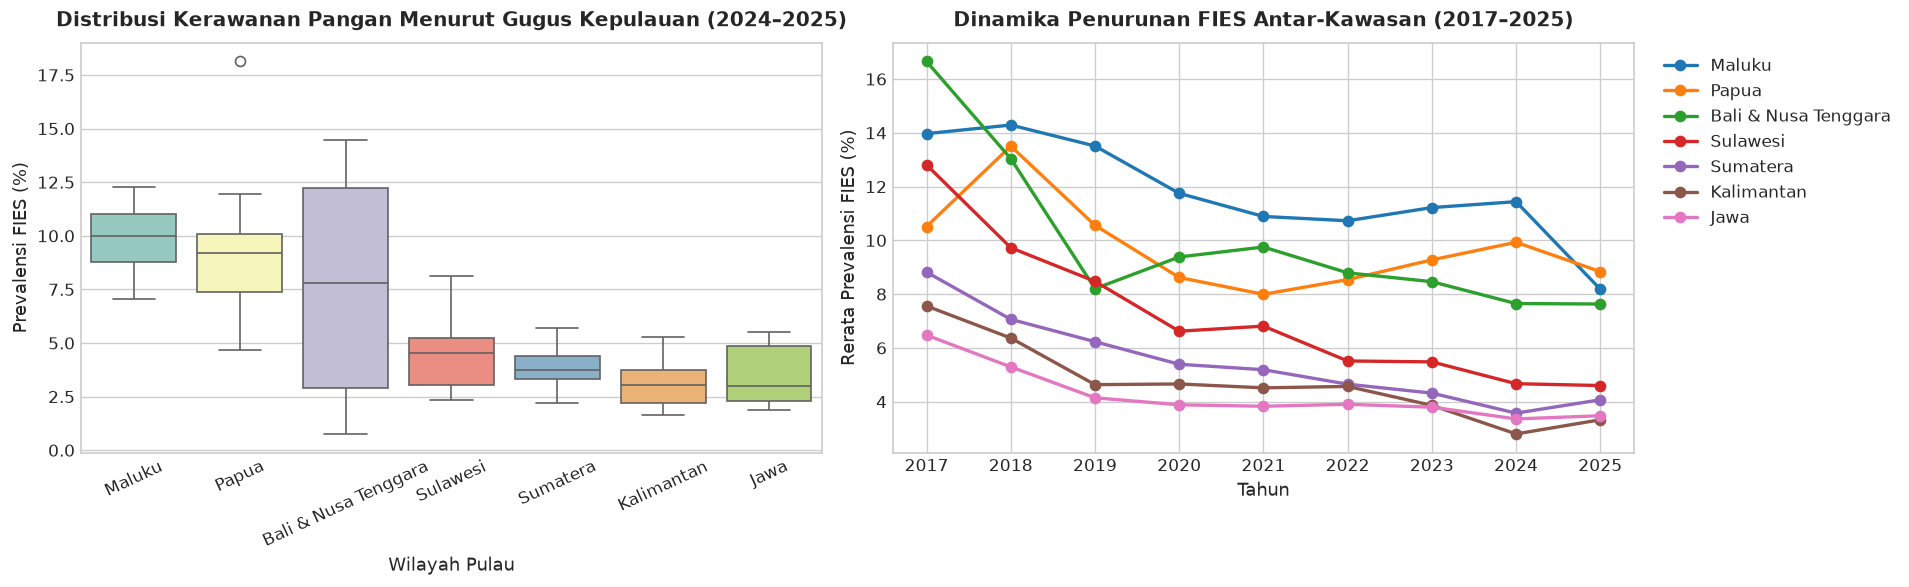

,count,mean,median,std,min,max
wilayah_pulau,,,,,,
Maluku,4,9.81,9.97,2.21,7.03,12.28
Papua,12,9.38,9.18,3.49,4.68,18.13
Bali & Nusa Tenggara,6,7.64,7.82,5.85,0.76,14.48
Sulawesi,12,4.64,4.52,1.77,2.32,8.11
Sumatera,20,3.82,3.76,0.85,2.22,5.69
Kalimantan,10,3.06,3.06,1.17,1.66,5.27
Jawa,12,3.42,2.98,1.35,1.88,5.53


In [ ]:
# Analisis Antar-Kawasan Pulau (2024–2025)
df_recent = df_fies_prov[df_fies_prov['tahun'] >= 2024]
order_pulau = df_recent.groupby('wilayah_pulau')['fies'].median().sort_values(ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Boxplot per pulau
sns.boxplot(data=df_recent, x='wilayah_pulau', y='fies', order=order_pulau, palette='Set3', ax=axes[0])
axes[0].set_title('Distribusi Kerawanan Pangan Menurut Gugus Kepulauan (2024–2025)', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('Wilayah Pulau', fontsize=11)
axes[0].set_ylabel('Prevalensi FIES (%)', fontsize=11)
axes[0].tick_params(axis='x', rotation=25)

# Plot 2: Tren per wilayah pulau dari waktu ke waktu
pulau_trend = df_fies_prov.groupby(['tahun', 'wilayah_pulau'])['fies'].mean().reset_index()
for p in order_pulau:
    sub = pulau_trend[pulau_trend['wilayah_pulau'] == p]
    axes[1].plot(sub['tahun'], sub['fies'], marker='o', label=p, linewidth=2)

axes[1].set_title('Dinamika Penurunan FIES Antar-Kawasan (2017–2025)', fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel('Tahun', fontsize=11)
axes[1].set_ylabel('Rerata Prevalensi FIES (%)', fontsize=11)
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

# Ringkasan per pulau
summary_pulau = df_recent.groupby('wilayah_pulau')['fies'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).loc[order_pulau]
display(summary_pulau.round(2))


## 📉 8. Evaluasi Akselerasi Penurunan: Provinsi dengan Kemajuan Tercepat (2017–2025)

Dengan mengukur $\Delta 	ext{FIES} = 	ext{FIES}_{2025} - 	ext{FIES}_{2017}$, kita dapat melihat provinsi mana yang mencatatkan lompatan keberhasilan pengentasan kerawanan pangan terbesar di Indonesia.


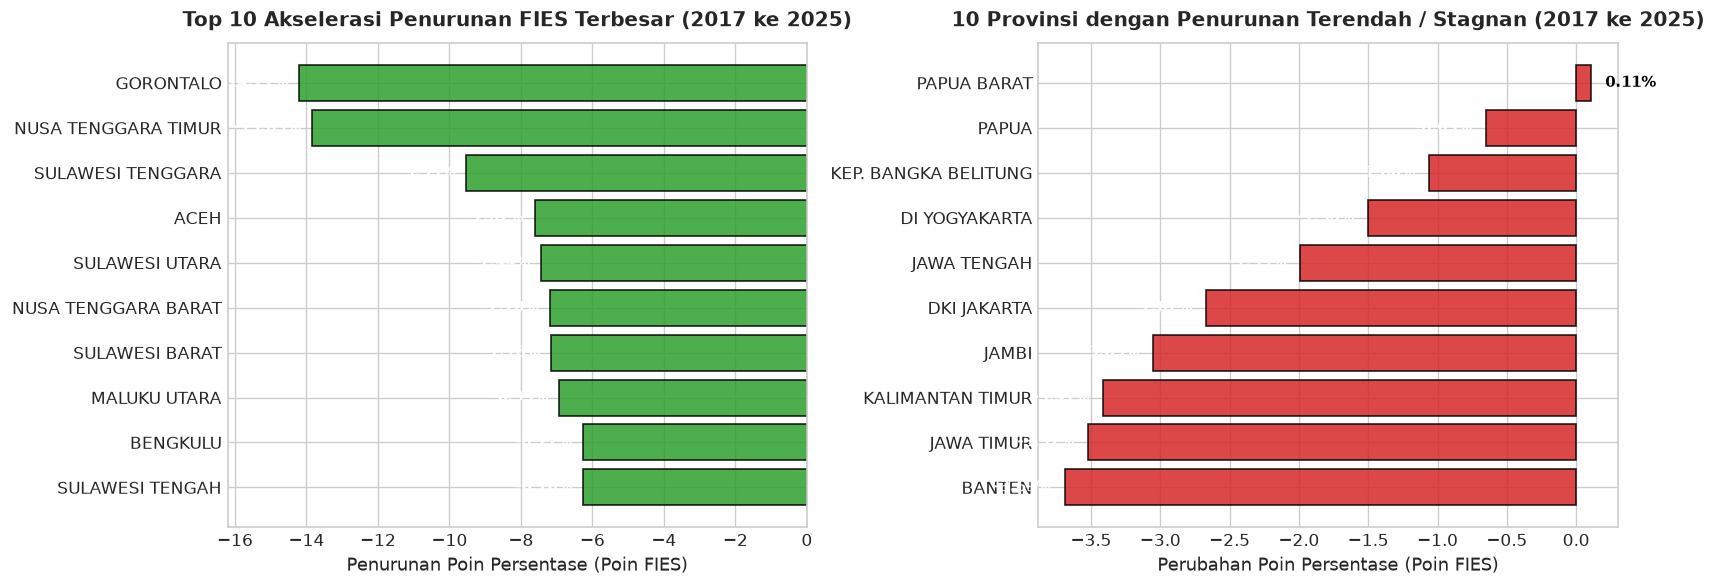

Rincian 5 Provinsi dengan Kemajuan Paling Spektakuler:


,provinsi,fies_2017,fies_2025,delta
28,GORONTALO,19.36,5.15,-14.21
18,NUSA TENGGARA TIMUR,27.54,13.69,-13.85
27,SULAWESI TENGGARA,11.85,2.32,-9.53
0,ACEH,11.35,3.73,-7.62
24,SULAWESI UTARA,11.94,4.50,-7.44
17,NUSA TENGGARA BARAT,15.13,7.93,-7.20
29,SULAWESI BARAT,11.69,4.53,-7.16
31,MALUKU UTARA,13.96,7.03,-6.93
6,BENGKULU,9.20,2.93,-6.27
25,SULAWESI TENGAH,14.37,8.11,-6.26


In [8]:
# Menghitung delta perubahan 2017 ke 2025 untuk provinsi yang memiliki data lengkap
df_wide_clean = df_fies_wide[df_fies_wide['provinsi'] != 'INDONESIA'].dropna(subset=['fies_2017', 'fies_2025']).copy()
df_wide_clean['delta'] = df_wide_clean['fies_2025'] - df_wide_clean['fies_2017']

top_progress = df_wide_clean.sort_values(by='delta', ascending=True).head(10)
least_progress = df_wide_clean.sort_values(by='delta', ascending=False).head(10)

plt.figure(figsize=(14, 5))

# Plot Progress Terbesar
plt.subplot(1, 2, 1)
bars = plt.barh(top_progress['provinsi'][::-1], top_progress['delta'][::-1], color='#2ca02c', edgecolor='black', alpha=0.85)
plt.title('Top 10 Akselerasi Penurunan FIES Terbesar (2017 ke 2025)', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('Penurunan Poin Persentase (Poin FIES)', fontsize=11)
plt.xlim(min(top_progress['delta']) - 2, 0)
for bar in bars:
    w = bar.get_width()
    plt.text(w - 0.3, bar.get_y() + bar.get_height()/2, f"{w:.2f}%", va='center', ha='right', fontsize=9, fontweight='bold', color='white')

# Plot Terkecil / Stagnan
plt.subplot(1, 2, 2)
bars2 = plt.barh(least_progress['provinsi'][::-1], least_progress['delta'][::-1], color='#d62728', edgecolor='black', alpha=0.85)
plt.title('10 Provinsi dengan Penurunan Terendah / Stagnan (2017 ke 2025)', fontsize=12, fontweight='bold', pad=10)
plt.xlabel('Perubahan Poin Persentase (Poin FIES)', fontsize=11)
for bar in bars2:
    w = bar.get_width()
    ha = 'left' if w >= 0 else 'right'
    col = 'black' if w >= 0 else 'white'
    offset = 0.1 if w >= 0 else -0.1
    plt.text(w + offset, bar.get_y() + bar.get_height()/2, f"{w:.2f}%", va='center', ha=ha, fontsize=9, fontweight='bold', color=col)

plt.tight_layout()
plt.show()

print("Rincian 5 Provinsi dengan Kemajuan Paling Spektakuler:")
display(top_progress[['provinsi', 'fies_2017', 'fies_2025', 'delta']].round(2))


## ⛰️ 9. Analisis Khusus: Tantangan 4 Provinsi Pemekaran Baru Papua (DOB)

Tahun 2024 dan 2025 menandai pertama kalinya BPS merilis data FIES resmi untuk 4 Daerah Otonom Baru (DOB) di Tanah Papua:
- **Papua Selatan**
- **Papua Tengah**
- **Papua Pegunungan**
- **Papua Barat Daya**

Bagaimana profil kerawanan pangan mereka dibanding provinsi induk (Papua & Papua Barat) dan rerata nasional?


<Figure size 1200x600 with 0 Axes>

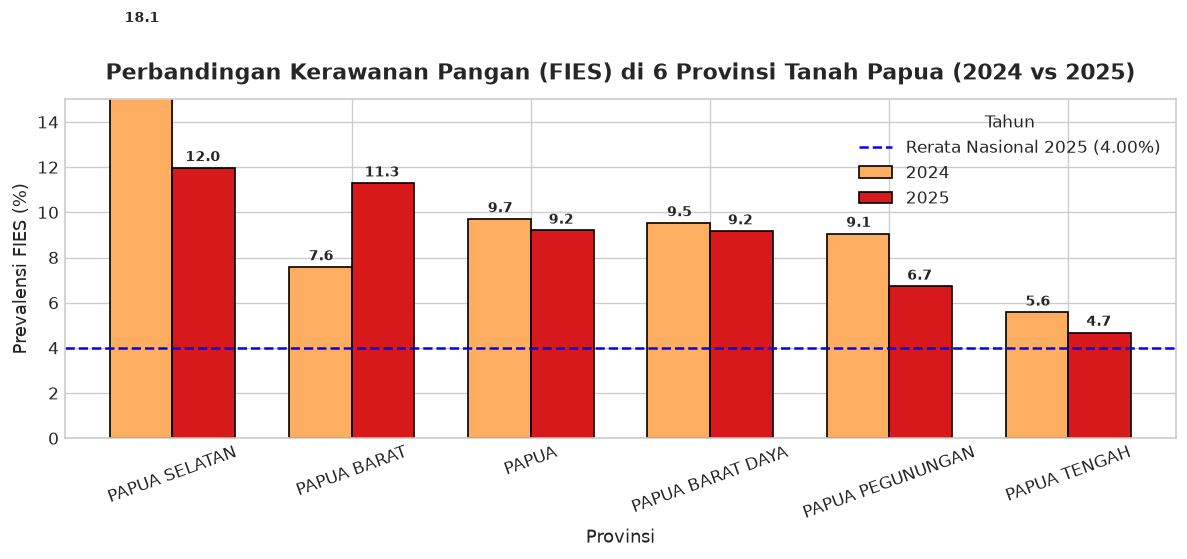

tahun,2024,2025
provinsi,,
PAPUA SELATAN,18.13,11.97
PAPUA BARAT,7.58,11.29
PAPUA,9.71,9.20
PAPUA BARAT DAYA,9.53,9.17
PAPUA PEGUNUNGAN,9.06,6.72
PAPUA TENGAH,5.57,4.68


In [9]:
# Filter data seluruh provinsi di Tanah Papua untuk tahun 2024 dan 2025
papua_provinces = ['PAPUA', 'PAPUA BARAT', 'PAPUA BARAT DAYA', 'PAPUA SELATAN', 'PAPUA TENGAH', 'PAPUA PEGUNUNGAN']
df_papua_dob = df_fies_all[(df_fies_all['provinsi'].isin(papua_provinces)) & (df_fies_all['tahun'] >= 2024)]

pivot_papua = df_papua_dob.pivot(index='provinsi', columns='tahun', values='fies').sort_values(by=2025, ascending=False)

plt.figure(figsize=(10, 5))
pivot_papua.plot(kind='bar', figsize=(10, 5), color=['#fdae61', '#d7191c'], edgecolor='black', width=0.7)
plt.axhline(y=4.00, color='blue', linestyle='--', label='Rerata Nasional 2025 (4.00%)')
plt.title('Perbandingan Kerawanan Pangan (FIES) di 6 Provinsi Tanah Papua (2024 vs 2025)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Provinsi', fontsize=11)
plt.ylabel('Prevalensi FIES (%)', fontsize=11)
plt.ylim(0, 15)
plt.xticks(rotation=20)
plt.legend(title='Tahun')

for i, prov in enumerate(pivot_papua.index):
    v24 = pivot_papua.loc[prov, 2024]
    v25 = pivot_papua.loc[prov, 2025]
    plt.text(i - 0.17, v24 + 0.3, f"{v24:.1f}", ha='center', fontsize=8.5, fontweight='bold')
    plt.text(i + 0.17, v25 + 0.3, f"{v25:.1f}", ha='center', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.show()

display(pivot_papua.round(2))


## 🎯 10. Sintesis Storytelling Data & Rekomendasi Kebijakan

### 💡 Temuan Utama (Key Insights)
1. **Lompatan Penurunan Bersejarah:**
   Tingkat kerawanan pangan sedang atau berat di Indonesia mengalami penurunan konsisten dan masif dari **8,66% (2017) menjadi 4,00% (2025)**. Penurunan sebesar 4,66 poin persentase ini membuktikan efektivitas program perlindungan sosial pangan nasional (seperti Bansos Beras CBP, Program Sembako/BPNT, dan stabilitas pasokan pangan Bapanas).
2. **Kisah Sukses Akselerasi Daerah:**
   - **Provinsi Gorontalo:** Berhasil memangkas FIES dari **19,36% (2017) menjadi 5,15% (2025)** (penurunan spektakuler -14,21 poin).
   - **Nusa Tenggara Timur (NTT):** Mengurangi FIES dari **27,54% (2017) menjadi 13,69% (2025)** (turun -13,85 poin), meskipun NTT masih menjadi provinsi dengan FIES tertinggi di Indonesia.
3. **Disparitas Ekstrem Kawasan Timur:**
   - Provinsi dengan kerawanan pangan terendah (< 2%): **Bali (1,28%)**, **Kalimantan Selatan (1,66%)**, dan **Jawa Timur (2,06%)**.
   - Provinsi dengan kerawanan pangan tertinggi (> 9%–13%): **NTT (13,69%)**, **Papua Selatan (11,97%)**, **Papua Barat (11,29%)**, **Maluku (9,34%)**, dan **Papua (9,20%)**.
4. **Tantangan Daerah Otonom Baru (DOB) Papua:**
   Rilis data perdana 2024–2025 memperlihatkan bahwa Papua Selatan (11,97%) dan Papua Barat (11,29%) mencatatkan kerawanan pangan hampir **tiga kali lipat di atas rata-rata nasional**, menuntut perhatian infrastruktur logistik yang mendesak.

---

### 📋 Rekomendasi untuk Presentasi & Kebijakan
1. **Fokus Target Intervensi Kawasan Timur (KTI):** Kebijakan ketahanan pangan harus bertransformasi dari program seragam nasional (*one size fits all*) menjadi kebijakan berbasis spasial kepulauan dan dataran tinggi (khususnya NTT, Maluku, dan Tanah Papua).
2. **Replikasi Model Keberhasilan Gorontalo & Sultra:** Melakukan transfer pengetahuan mengenai tata kelola logistik pangan dan sinergi pertanian lokal yang berhasil diterapkan di Gorontalo dan Sulawesi Tenggara ke daerah-daerah lain yang mengalami stagnasi.
3. **Penyempurnaan Rantai Dingin (*Cold Chain*) & Konektivitas Laut:** Kerawanan pangan sedang di NTT dan Maluku banyak dipicu oleh kerentanan pasokan ikan dan protein hewani saat musim angin kencang; penyediaan kapal pendingin dan lumbung pangan pulau sangat mendesak.
